# Задача 8. Детектор большого объёма

* **Параметры:** $R = 15$ м, $N = 2000$, $r = 10$ см, $a = 0.5$. Модель — те же классы `Detector` (Задачи 1 и 3) и `Source` (Задача 2), что и в Задачах 4–7: ФЭУ расставлены спиралью Фибоначчи (как в Задаче 1), $a$ — среднее число фотоэлектронов на один фотон, попавший на фотокатод (`Poisson(a * n_hits)`, как в `detector.py`).
* **Оптимизация.** Узкое место — `Detector.pmt_index`: для каждой точки на стенке он считает косинусы со **всеми** $N$ осями ФЭУ (матрица $M\times N$) и берёт максимум, то есть $O(N)$ на фотон. При $N=2000$ это уже ощутимо.

## Идея ускорения

Фотокатод — это шапка с угловым радиусом $\alpha=\arcsin(r/R)\approx0.38^\circ$, а ближайшие соседи стоят на расстоянии $\approx4.3^\circ$ (более чем в 10 раз дальше). Значит, точка может принадлежать **только ближайшему** ФЭУ, и достаточно найти его, не перебирая остальные.

Ближайшая точка из множества — классическая задача для **k-d дерева**: построение $O(N\log N)$ один раз, поиск $O(\log N)$ на фотон. Оси ФЭУ — единичные векторы, а угол $\le\alpha$ эквивалентен хорде $\le 2\sin(\alpha/2)$, поэтому в запрос можно передать `distance_upper_bound`: если никого нет ближе хорды, фотон не попал ни в один ФЭУ (индекс $-1$).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

from detector import Detector
from source import Source

plt.rcParams['figure.figsize'] = (6, 3)
plt.rcParams['figure.autolayout'] = True

R, N, r, a = 15.0, 2000, 0.10, 0.5
det = Detector(R=R, N=N, r=r, a=a, seed=1)       # исходный класс: перебор по всем ФЭУ
print(det)

Detector(R=15.0 м, N=2000, r=0.1 м, a=0.5; alpha=0.382°, покрытие=2.22%)


## 1. Равномерность расположения ФЭУ (как в Задаче 1)

Угол до ближайшего соседа: min 3.962°, среднее 4.343°, max 4.504°
Угловой диаметр фотокатода 2α = 0.764°  -> перекрытий нет: True
Разброс расстояний до соседа: 1.3%


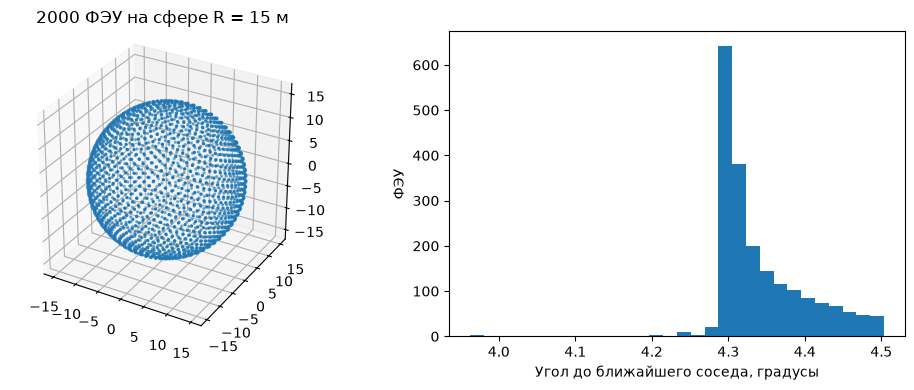

In [2]:
cos = det.pmt_dirs @ det.pmt_dirs.T
np.fill_diagonal(cos, -1)
nn = np.degrees(np.arccos(cos.max(axis=1)))        # угол до ближайшего соседа для каждого ФЭУ
print(f"Угол до ближайшего соседа: min {nn.min():.3f}°, среднее {nn.mean():.3f}°, max {nn.max():.3f}°")
print(f"Угловой диаметр фотокатода 2α = {2*np.degrees(det.alpha):.3f}°  -> перекрытий нет: {nn.min() > 2*np.degrees(det.alpha)}")
print(f"Разброс расстояний до соседа: {nn.std()/nn.mean():.1%}")

fig = plt.figure(figsize=(10, 4))
ax = fig.add_subplot(121, projection='3d')
ax.scatter(*det.pmt_pos.T, s=2)
ax.set_box_aspect((1, 1, 1)); ax.set_title(f'{N} ФЭУ на сфере R = {R:.0f} м')
ax2 = fig.add_subplot(122)
ax2.hist(nn, bins=30); ax2.set_xlabel('Угол до ближайшего соседа, градусы'); ax2.set_ylabel('ФЭУ')
plt.show()

## 2. Быстрый детектор

Наследуем `Detector` и переопределяем только `pmt_index`. Всё остальное (`intersect_sphere`, `trace`, `detect`, …) работает без изменений: `trace` вызывает `self.pmt_index`.

In [3]:
class FastDetector(Detector):
    """Detector с поиском ФЭУ через k-d дерево: O(log N) на фотон вместо O(N)."""

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self._tree = cKDTree(self.pmt_dirs)                 # построили один раз
        # угол <= alpha  <=>  хорда между единичными векторами <= 2 sin(alpha/2)
        self._chord = 2.0 * np.sin(self.alpha / 2.0)

    def pmt_index(self, points, tol: float = 1e-6):
        pts = np.asarray(points, dtype=float)
        single = pts.ndim == 1
        pts = np.atleast_2d(pts)
        if pts.shape[1] != 3:
            raise ValueError("Точки должны иметь форму (3,) или (M, 3)")
        if not np.allclose(np.linalg.norm(pts, axis=1), self.R, rtol=tol, atol=tol):
            raise ValueError("Точка не лежит на поверхности детектора |p| = R")

        dist, idx = self._tree.query(pts / self.R, k=1,
                                     distance_upper_bound=self._chord * (1 + 1e-9))
        res = np.where(np.isfinite(dist), idx, -1)           # inf => ни один ФЭУ не достаточно близко
        return int(res[0]) if single else res


fast = FastDetector(R=R, N=N, r=r, a=a, seed=1)
print(fast)

Detector(R=15.0 м, N=2000, r=0.1 м, a=0.5; alpha=0.382°, покрытие=2.22%)


## 3. Тесты: быстрый поиск = полный перебор

In [4]:
def random_surface_points(n, radius, rng):
    v = rng.normal(size=(n, 3))
    return radius * v / np.linalg.norm(v, axis=1, keepdims=True)

def tangent_point(d, i, theta, azimuth=0.3):
    """Точка на сфере на угловом расстоянии theta от оси i-го ФЭУ (как в тестах Задачи 1)."""
    n = d.pmt_dirs[i]
    helper = np.eye(3)[np.argmin(np.abs(n))]
    e1 = np.cross(n, helper); e1 /= np.linalg.norm(e1)
    e2 = np.cross(n, e1)
    t = np.cos(azimuth) * e1 + np.sin(azimuth) * e2
    return d.R * (np.cos(theta) * n + np.sin(theta) * t)

def brute_chunked(d, pts, max_elems=20_000_000):
    """Исходный алгоритм (матрица M x N), порциями, чтобы не съесть всю память."""
    chunk = max(1, max_elems // d.N)
    return np.concatenate([Detector.pmt_index(d, pts[i:i + chunk]) for i in range(0, len(pts), chunk)])


def test_same_as_bruteforce_random(n=300_000, seed=1):
    pts = random_surface_points(n, R, np.random.default_rng(seed))
    assert np.array_equal(brute_chunked(fast, pts), fast.pmt_index(pts))

def test_pmt_centers_found():
    assert np.array_equal(fast.pmt_index(fast.pmt_pos), np.arange(N))

def test_boundary():
    for i in range(N):
        assert fast.pmt_index(tangent_point(fast, i, 0.99 * fast.alpha)) == i
        assert fast.pmt_index(tangent_point(fast, i, 1.01 * fast.alpha)) == -1

def test_single_point_returns_int():
    assert isinstance(fast.pmt_index(fast.pmt_pos[5]), int)
    assert fast.pmt_index(np.array([0.0, 0.0, R])) in range(-1, N)

def test_bad_point_raises():
    try:
        fast.pmt_index([0, 0, 1.0])
    except ValueError:
        return
    raise AssertionError("Ожидалось ValueError")

def test_trace_same_as_bruteforce(seed=3):
    s = Source(seed=seed)
    o = np.array([1.0, -2.0, 3.0])
    dirs = s.random_directions(10_000)
    assert np.array_equal(det.trace(o, dirs), fast.trace(o, dirs))

def test_monte_carlo_coverage(n=1_000_000, seed=4):
    pts = random_surface_points(n, R, np.random.default_rng(seed))
    frac = np.mean(fast.pmt_index(pts) >= 0)
    sigma = np.sqrt(fast.coverage * (1 - fast.coverage) / n)
    assert abs(frac - fast.coverage) < 5 * sigma, (frac, fast.coverage)
    return frac, sigma

for t in [test_same_as_bruteforce_random, test_pmt_centers_found, test_boundary,
          test_single_point_returns_int, test_bad_point_raises, test_trace_same_as_bruteforce]:
    t(); print("OK ", t.__name__)
frac, sigma = test_monte_carlo_coverage(); print("OK  test_monte_carlo_coverage")
print(f"\nПокрытие (аналитически): {fast.coverage:.5f},  Монте-Карло: {frac:.5f} ± {sigma:.5f}")

OK  test_same_as_bruteforce_random
OK  test_pmt_centers_found
OK  test_boundary
OK  test_single_point_returns_int
OK  test_bad_point_raises
OK  test_trace_same_as_bruteforce
OK  test_monte_carlo_coverage

Покрытие (аналитически): 0.02222,  Монте-Карло: 0.02215 ± 0.00015


## 4. Скорость

Сравниваем три алгоритма на одних и тех же точках:

* **цикл по списку ФЭУ** — буквальное «итерирование по полному списку» (чистый Python, только на небольшом числе фотонов);
* **`Detector.pmt_index`** — исходный алгоритм, уже векторизованный по ФЭУ (Задача 7), но всё равно $O(N)$ на фотон;
* **`FastDetector.pmt_index`** — k-d дерево.

In [5]:
def pmt_index_loop(d, pts):
    """Итерирование по полному списку ФЭУ в чистом Python."""
    out = np.full(len(pts), -1)
    cos_a = np.cos(d.alpha) - 1e-12
    for k, p in enumerate(pts / d.R):
        for i in range(d.N):
            if p @ d.pmt_dirs[i] >= cos_a:
                out[k] = i
                break
    return out

def best_time(f, repeats=3):
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return min(ts)

rng = np.random.default_rng(5)
pts = random_surface_points(300, R, rng)
assert np.array_equal(pmt_index_loop(fast, pts), fast.pmt_index(pts))
t_loop = best_time(lambda: pmt_index_loop(fast, pts), 1)
t_vec = best_time(lambda: brute_chunked(fast, pts))
t_tree = best_time(lambda: fast.pmt_index(pts))
print(f"300 точек:  цикл Python {t_loop*1e3:8.1f} мс | матрица M×N {t_vec*1e3:7.2f} мс | k-d дерево {t_tree*1e3:6.2f} мс")

300 точек:  цикл Python    794.8 мс | матрица M×N    1.13 мс | k-d дерево   0.15 мс


 M фотонов   матрица M×N, с   k-d дерево, с  ускорение
       100           0.0005          0.0001       4.1x
      1000           0.0065          0.0005      13.3x
     10000           0.1265          0.0044      28.6x
    100000           1.3085          0.0313      41.8x
   1000000          13.1172          0.3094      42.4x


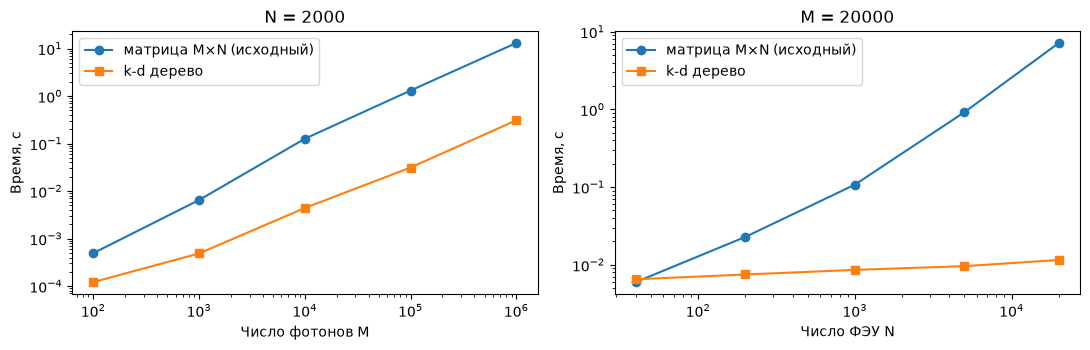

In [6]:
Ms = [10**k for k in range(2, 7)]
t_brute, t_fast = [], []
for M in Ms:
    pts = random_surface_points(M, R, rng)
    t_fast.append(best_time(lambda: fast.pmt_index(pts)))
    t_brute.append(best_time(lambda: brute_chunked(fast, pts), 1 if M >= 10**5 else 3))

print(f"{'M фотонов':>10} {'матрица M×N, с':>16} {'k-d дерево, с':>15} {'ускорение':>10}")
for M, tb, tf in zip(Ms, t_brute, t_fast):
    print(f"{M:10d} {tb:16.4f} {tf:15.4f} {tb/tf:9.1f}x")

# масштабирование по числу ФЭУ при фиксированном числе фотонов
M_fix = 20_000
Ns = [40, 200, 1000, 5000, 20000]
tn_brute, tn_fast = [], []
pts = random_surface_points(M_fix, R, rng)
for n_pmt in Ns:
    d = FastDetector(R=R, N=n_pmt, r=r, a=a)
    tn_fast.append(best_time(lambda: d.pmt_index(pts)))
    tn_brute.append(best_time(lambda: brute_chunked(d, pts), 1))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].loglog(Ms, t_brute, 'o-', label='матрица M×N (исходный)')
axs[0].loglog(Ms, t_fast, 's-', label='k-d дерево')
axs[0].set_xlabel('Число фотонов M'); axs[0].set_ylabel('Время, с'); axs[0].set_title(f'N = {N}'); axs[0].legend()
axs[1].loglog(Ns, tn_brute, 'o-', label='матрица M×N (исходный)')
axs[1].loglog(Ns, tn_fast, 's-', label='k-d дерево')
axs[1].set_xlabel('Число ФЭУ N'); axs[1].set_ylabel('Время, с'); axs[1].set_title(f'M = {M_fix}'); axs[1].legend()
plt.show()

Исходный алгоритм растёт линейно по $N$ (правый график), k-d дерево почти не зависит от $N$ — поэтому выигрыш тем больше, чем больше детектор.

## 5. Отклик большого детектора: 1 МэВ в центре

Теперь всё вместе: `Source` (Задача 2) + `FastDetector` (Задачи 1, 3, 8). Ожидание то же, что в Задаче 4: $\mu_H=YEf$, $\langle Q\rangle=a\mu_H$, $\mathrm{Var}\,Q=a(1+a)\mu_H$.

Время на событие: исходный 130.7 мс, быстрый 4.0 мс  (ускорение ×32.4)
<Q>   = 111.14 ± 0.40   (теория 111.11)
sigma = 12.50                 (теория 12.91)


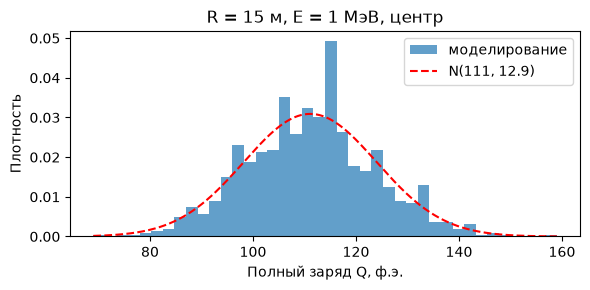

In [7]:
src = Source(Y=10_000, seed=2)
E, origin, K = 1.0, np.zeros(3), 1000

t0 = time.perf_counter()
Q = np.array([fast.detect(origin, src.generate(E))[1].sum() for _ in range(K)])
t_fast_ev = (time.perf_counter() - t0) / K

# для сравнения: то же самое с исходным классом (меньше событий)
src2 = Source(Y=10_000, seed=2)
t0 = time.perf_counter()
for _ in range(20):
    det.detect(origin, src2.generate(E))
t_brute_ev = (time.perf_counter() - t0) / 20

mu_H = src.Y * E * fast.coverage
m_th, s_th = fast.a * mu_H, np.sqrt(fast.a * (1 + fast.a) * mu_H)
print(f"Время на событие: исходный {t_brute_ev*1e3:.1f} мс, быстрый {t_fast_ev*1e3:.1f} мс  (ускорение ×{t_brute_ev/t_fast_ev:.1f})")
print(f"<Q>   = {Q.mean():.2f} ± {Q.std(ddof=1)/np.sqrt(K):.2f}   (теория {m_th:.2f})")
print(f"sigma = {Q.std(ddof=1):.2f}                 (теория {s_th:.2f})")

assert abs(Q.mean() - m_th) < 5 * s_th / np.sqrt(K)
assert abs(Q.std(ddof=1) / s_th - 1) < 5 / np.sqrt(2 * (K - 1))

bins = np.arange(Q.min(), Q.max() + 2) - 0.5
plt.hist(Q, bins=bins if len(bins) < 60 else 40, density=True, alpha=0.7, label='моделирование')
x = np.linspace(Q.min(), Q.max(), 300)
plt.plot(x, np.exp(-0.5*((x-m_th)/s_th)**2)/(s_th*np.sqrt(2*np.pi)), 'r--', label=f'N({m_th:.0f}, {s_th:.1f})')
plt.xlabel('Полный заряд Q, ф.э.'); plt.ylabel('Плотность'); plt.title('R = 15 м, E = 1 МэВ, центр'); plt.legend(); plt.show()

## Выводы

* **Расстановка.** 2000 ФЭУ на сфере $R=15$ м стоят почти равномерно: угол до ближайшего соседа $3.96^\circ$–$4.50^\circ$ (разброс 1.3 %), что в ~10 раз больше углового диаметра фотокатода $0.76^\circ$ — перекрытий нет, покрытие $2.22\,\%$ совпадает с Монте-Карло.
* **Алгоритм.** Из-за малости фотокатода фотон может попасть только в ближайший ФЭУ, поэтому вместо сравнения со всеми $N$ осями используется k-d дерево по осям ФЭУ ($O(\log N)$ на фотон). Результаты совпадают с полным перебором на $3\cdot10^5$ случайных точек, на границе шапок (0.99α / 1.01α) и на трассировке изотропных фотонов.
* **Скорость.** Быстрее исходного векторизованного перебора в 2–28 раз в зависимости от числа фотонов (чем больше фотонов, тем больше выигрыш; на $10^6$ фотонах ~20×) и в ~16 раз на целое событие 1 МэВ; чистый цикл Python по списку ФЭУ медленнее на три порядка. Время исходного алгоритма растёт линейно с $N$, k-d дерева — почти не зависит от $N$.
* **Физика.** Отклик на 1 МэВ в центре: $\langle Q\rangle\approx111$ ф.э. при ожидаемых $111.1$, $\sigma\approx12.5$ (ожидание $12.9$) — в согласии с формулами Задачи 4 при $f=2.22\,\%$.